# Funnel analysis по данным интернет-магазина

В этом проекте я посмотрел поведение пользователей в интернет-магазине на выборке из 1 млн событий.

**Основная задача** — понять, как пользователи проходят путь от просмотра до покупки, где теряются, есть ли странности в данных и какие продуктовые гипотезы можно проверить.

**Стек**: Python, Pandas, NumPy, Matplotlib, Seaborn, Kaggle Hub / Kaggle API.

Сначала я считал воронку просто по наличию событий `view`, `cart`, `purchase`, но потом увидел проблему: покупок в сессиях оказалось больше, чем корзин. Поэтому пересобрал воронку по времени внутри сессии:

`первый view -> cart после него -> purchase после cart`

Также отдельно посмотрел, сколько покупок происходит вообще без события корзины.

In [15]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

SAMPLE_FILE = 'ecommerce_sample.csv'

if os.path.exists(SAMPLE_FILE):
    df = pd.read_csv(SAMPLE_FILE)
else:
    import kagglehub
    path = kagglehub.dataset_download(
        'mkechinov/ecommerce-behavior-data-from-multi-category-store'
    )
    df = pd.read_csv(os.path.join(path, '2019-Oct.csv'), nrows=1_000_000)

# Базовая очистка
df = df.dropna(subset=['user_session', 'event_type']).copy()

df['user_session'] = df['user_session'].astype(str)
df['event_type'] = df['event_type'].astype(str)
df['event_time'] = pd.to_datetime(df['event_time'], errors='coerce')
df['price'] = pd.to_numeric(df['price'], errors='coerce')

df = df.dropna(subset=['event_time'])

# Категория верхнего уровня
if 'category_group' not in df.columns:
    if 'category_code' in df.columns:
        df['category_group'] = df['category_code'].apply(
            lambda x: str(x).split('.')[0] if pd.notnull(x) else 'unknown'
        )
    else:
        df['category_group'] = 'unknown'
else:
    df['category_group'] = df['category_group'].fillna('unknown').astype(str)

# Продуктовый ценовой сегмент, если есть старое поле price_category
if 'product_price_category' not in df.columns:
    if 'price_category' in df.columns:
        df = df.rename(columns={'price_category': 'product_price_category'})
    else:
        price_rank = df['price'].fillna(0).rank(method='first')
        df['product_price_category'] = pd.qcut(
            price_rank,
            q=3,
            labels=['low', 'medium', 'high']
        )

# Сортировка важна для последовательной воронки
df = df.sort_values(['user_session', 'event_time']).reset_index(drop=True)

print(f'Строк: {len(df):,}')
print(f'Уникальных сессий: {df["user_session"].nunique():,}')

print('\nКоличество событий:')
print(df['event_type'].value_counts())

print('\nДоли событий, %:')
print((df['event_type'].value_counts(normalize=True) * 100).round(2))

print('\nПропуски в критичных полях:')
print(
    df[['user_session', 'event_time', 'event_type', 'price', 'category_code']]
    .isna()
    .sum()
)

Строк: 1,000,000
Уникальных сессий: 226,374

Количество событий:
event_type
view        968513
purchase     16848
cart         14639
Name: count, dtype: int64

Доли событий, %:
event_type
view       96.85
purchase    1.68
cart        1.46
Name: proportion, dtype: float64

Пропуски в критичных полях:
user_session          0
event_time            0
event_type            0
price                 0
category_code    318131
dtype: int64


In [8]:
first_times = (
    df.groupby(['user_session', 'event_type'])['event_time']
      .min()
      .unstack()
      .reindex(columns=['view', 'cart', 'purchase'])
)

coverage = pd.DataFrame({
    'sessions_with_event': first_times.notna().sum()
})

coverage['share_of_all_sessions_%'] = (
    coverage['sessions_with_event'] / df['user_session'].nunique() * 100
).round(2)

purchase_sessions = first_times.index[first_times['purchase'].notna()]
cart_sessions = first_times.index[first_times['cart'].notna()]

purchase_without_cart_count = len(
    set(purchase_sessions).difference(set(cart_sessions))
)

purchase_with_cart_count = len(
    set(purchase_sessions).intersection(set(cart_sessions))
)

purchase_without_cart_share = (
    purchase_without_cart_count / max(len(purchase_sessions), 1) * 100
)

print('=== ПОКРЫТИЕ СЕССИЙ СОБЫТИЯМИ, не последовательная воронка ===')
print(coverage)

print(f'\nСессий с покупкой: {len(purchase_sessions):,}')
print(f'Сессий с корзиной: {len(cart_sessions):,}')

print(
    f'Сессий с покупкой без корзины: {purchase_without_cart_count:,} '
    f'({purchase_without_cart_share:.2f}%)'
)

print(f'Сессий с покупкой и корзиной: {purchase_with_cart_count:,}')

=== ПОКРЫТИЕ СЕССИЙ СОБЫТИЯМИ, не последовательная воронка ===
            sessions_with_event  share_of_all_sessions_%
event_type                                              
view                     226278                    99.96
cart                       8894                     3.93
purchase                  14316                     6.32

Сессий с покупкой: 14,316
Сессий с корзиной: 8,894
Сессий с покупкой без корзины: 9,347 (65.29%)
Сессий с покупкой и корзиной: 4,969


In [9]:
first_view = (
    df.loc[df['event_type'] == 'view']
      .groupby('user_session')['event_time']
      .min()
      .rename('first_view')
)

cart_after_view = (
    df.loc[df['event_type'] == 'cart']
      .merge(first_view, left_on='user_session', right_index=True)
      .query('event_time >= first_view')
      .groupby('user_session')['event_time']
      .min()
      .rename('first_cart_after_view')
)

purchase_after_cart = (
    df.loc[df['event_type'] == 'purchase']
      .merge(cart_after_view, left_on='user_session', right_index=True)
      .query('event_time >= first_cart_after_view')
      .groupby('user_session')['event_time']
      .min()
      .rename('first_purchase_after_cart')
)

purchase_after_view = (
    df.loc[df['event_type'] == 'purchase']
      .merge(first_view, left_on='user_session', right_index=True)
      .query('event_time >= first_view')
      .groupby('user_session')['event_time']
      .min()
      .rename('first_purchase_after_view')
)

funnel_seq = pd.DataFrame(
    {
        'sessions': [
            first_view.count(),
            cart_after_view.count(),
            purchase_after_cart.count()
        ]
    },
    index=['view', 'cart', 'purchase']
)

funnel_seq['conversion_overall_%'] = (
    funnel_seq['sessions'] / funnel_seq.loc['view', 'sessions'] * 100
).round(2)

funnel_seq['conversion_step_%'] = (
    funnel_seq['sessions'] / funnel_seq['sessions'].shift(1) * 100
).round(2)

direct_purchase_sessions = purchase_after_view.index.difference(
    purchase_after_cart.index
)

print('=== ПОСЛЕДОВАТЕЛЬНАЯ ВОРОНКА: view -> cart -> purchase ===')
print(funnel_seq)

print(
    '\nСессий с покупкой после просмотра, но без корректного шага cart -> purchase: '
    f'{len(direct_purchase_sessions):,}'
)

print(
    'Доля таких сессий от всех покупок после просмотра: '
    f'{len(direct_purchase_sessions) / max(purchase_after_view.count(), 1) * 100:.2f}%'
)

=== ПОСЛЕДОВАТЕЛЬНАЯ ВОРОНКА: view -> cart -> purchase ===
          sessions  conversion_overall_%  conversion_step_%
view        226278                100.00                NaN
cart          8850                  3.91               3.91
purchase      4928                  2.18              55.68

Сессий с покупкой после просмотра, но без корректного шага cart -> purchase: 9,221
Доля таких сессий от всех покупок после просмотра: 65.17%


In [10]:
time_to_purchase = (
    purchase_after_view.to_frame()
    .join(first_view, how='inner')
)

time_to_purchase['minutes_to_first_purchase_after_view'] = (
    time_to_purchase['first_purchase_after_view'] -
    time_to_purchase['first_view']
).dt.total_seconds() / 60

time_to_purchase = time_to_purchase[
    time_to_purchase['minutes_to_first_purchase_after_view'] >= 0
]

if len(time_to_purchase) > 0:
    median_time_to_purchase = (
        time_to_purchase['minutes_to_first_purchase_after_view'].median()
    )
    p25_time = (
        time_to_purchase['minutes_to_first_purchase_after_view'].quantile(0.25)
    )
    p75_time = (
        time_to_purchase['minutes_to_first_purchase_after_view'].quantile(0.75)
    )
else:
    median_time_to_purchase = np.nan
    p25_time = np.nan
    p75_time = np.nan

purchase_session_ids = df.loc[
    df['event_type'] == 'purchase',
    'user_session'
].unique()

session_duration = (
    df[df['user_session'].isin(purchase_session_ids)]
      .groupby('user_session')['event_time']
      .agg(lambda x: (x.max() - x.min()).total_seconds() / 60)
)

if len(session_duration) > 0:
    median_session_duration = session_duration.median()
else:
    median_session_duration = np.nan

print('=== ВРЕМЕННЫЕ МЕТРИКИ ===')

print(
    f'Медиана от первого view до первой purchase: '
    f'{median_time_to_purchase:.2f} мин'
)

print(
    f'P25 / P75: '
    f'{p25_time:.2f} / {p75_time:.2f} мин'
)

print(
    f'Медиана полной длительности сессий с покупкой: '
    f'{median_session_duration:.2f} мин'
)

=== ВРЕМЕННЫЕ МЕТРИКИ ===
Медиана от первого view до первой purchase: 2.83 мин
P25 / P75: 1.33 / 6.15 мин
Медиана полной длительности сессий с покупкой: 3.95 мин


In [11]:
session_base = pd.DataFrame(index=first_view.index)

session_base['has_cart_after_view'] = session_base.index.isin(
    cart_after_view.index
)

session_base['has_purchase_after_cart'] = session_base.index.isin(
    purchase_after_cart.index
)

session_max_price = df.groupby('user_session')['price'].max(min_count=1)

session_base['max_price'] = session_max_price.reindex(session_base.index)
session_base['max_price_filled'] = session_base['max_price'].fillna(0)

try:
    session_base['session_price_category'] = pd.qcut(
        session_base['max_price_filled'].rank(method='first'),
        q=3,
        labels=['low', 'medium', 'high']
    )
except ValueError:
    session_base['session_price_category'] = pd.cut(
        session_base['max_price_filled'].rank(method='first'),
        bins=3,
        labels=['low', 'medium', 'high']
    )

price_funnel = (
    session_base.groupby('session_price_category', observed=True)
    .agg(
        view_sessions=('max_price_filled', 'size'),
        cart_sessions=('has_cart_after_view', 'sum'),
        purchase_sessions=('has_purchase_after_cart', 'sum')
    )
    .reset_index()
)

price_funnel['overall_sequential_CR_%'] = (
    price_funnel['purchase_sessions'] /
    price_funnel['view_sessions'] * 100
).round(2)

price_funnel['cart_to_purchase_%'] = (
    price_funnel['purchase_sessions'] /
    price_funnel['cart_sessions'].replace(0, np.nan) * 100
).round(2)

if price_funnel.empty:
    best_price_segment = pd.Series({
        'session_price_category': '—',
        'overall_sequential_CR_%': np.nan
    })
elif price_funnel['overall_sequential_CR_%'].notna().any():
    best_price_segment = price_funnel.loc[
        price_funnel['overall_sequential_CR_%'].idxmax()
    ]
else:
    best_price_segment = price_funnel.iloc[0]

print('=== ЦЕНОВЫЕ СЕГМЕНТЫ НА УРОВНЕ СЕССИИ, взаимоисключающие по макс. цене ===')
print(price_funnel.to_string(index=False))

print(
    f'\nЛучший сегмент по последовательной конверсии: '
    f'{best_price_segment["session_price_category"]} '
    f'({best_price_segment["overall_sequential_CR_%"]:.2f}%)'
)

=== ЦЕНОВЫЕ СЕГМЕНТЫ НА УРОВНЕ СЕССИИ, взаимоисключающие по макс. цене ===
session_price_category  view_sessions  cart_sessions  purchase_sessions  overall_sequential_CR_%  cart_to_purchase_%
                   low          75426           2026               1000                     1.33               49.36
                medium          75426           3607               2083                     2.76               57.75
                  high          75426           3217               1845                     2.45               57.35

Лучший сегмент по последовательной конверсии: medium (2.76%)


In [12]:
cat_counts = df.pivot_table(
    index='category_group',
    columns='event_type',
    values='event_time',
    aggfunc='count'
).fillna(0)

for col in ['view', 'cart', 'purchase']:
    if col not in cat_counts.columns:
        cat_counts[col] = 0

revenue = (
    df.loc[df['event_type'] == 'purchase']
      .groupby('category_group')['price']
      .sum()
      .rename('revenue')
)

cat_event = (
    cat_counts[['view', 'cart', 'purchase']]
    .join(revenue, how='left')
    .fillna({'revenue': 0})
    .reset_index()
)

cat_event['event_CR_%'] = (
    cat_event['purchase'] /
    cat_event['view'].replace(0, np.nan) * 100
).round(2)

cat_event['proxy_AOV'] = (
    cat_event['revenue'] /
    cat_event['purchase'].replace(0, np.nan)
).round(2)

total_revenue = cat_event['revenue'].sum()

if total_revenue > 0:
    cat_event['revenue_share_%'] = (
        cat_event['revenue'] / total_revenue * 100
    ).round(2)
else:
    cat_event['revenue_share_%'] = 0.0

known = (
    cat_event[cat_event['category_group'] != 'unknown']
    .sort_values('revenue', ascending=False)
    .copy()
)

unknown = cat_event[cat_event['category_group'] == 'unknown'].copy()

total_events = len(df)

unknown_events = (
    unknown[['view', 'cart', 'purchase']].sum().sum()
    if not unknown.empty else 0
)

print('=== ТОП ИЗВЕСТНЫХ КАТЕГОРИЙ ПО ВЫРУЧКЕ, event-based метрики ===')

print(
    known.head(10)[
        [
            'category_group',
            'view',
            'cart',
            'purchase',
            'event_CR_%',
            'proxy_AOV',
            'revenue',
            'revenue_share_%'
        ]
    ].to_string(index=False)
)

print('\n=== ДИАГНОСТИКА КАТЕГОРИИ UNKNOWN ===')

if unknown.empty:
    print('Строк с unknown нет.')
else:
    print(
        unknown[
            [
                'category_group',
                'view',
                'cart',
                'purchase',
                'revenue',
                'revenue_share_%'
            ]
        ].to_string(index=False)
    )

    print(
        f'\nДоля unknown от всех событий: '
        f'{unknown_events / total_events * 100:.2f}%'
    )

=== ТОП ИЗВЕСТНЫХ КАТЕГОРИЙ ПО ВЫРУЧКЕ, event-based метрики ===
category_group       view      cart  purchase  event_CR_%  proxy_AOV      revenue  revenue_share_%
   electronics 363,833.00 12,321.00  9,890.00        2.72     426.67 4,219,731.15            77.63
     computers  56,160.00    144.00    715.00        1.27     436.48   312,085.11             5.74
    appliances 113,360.00    508.00  1,757.00        1.55     161.16   283,155.11             5.21
     furniture  26,438.00     14.00    166.00        0.63     192.20    31,905.55             0.59
  construction  18,687.00    134.00    206.00        1.10     106.43    21,925.53             0.40
          auto  24,135.00    145.00    192.00        0.80     111.93    21,490.70             0.40
          kids  12,109.00     25.00    127.00        1.05     141.03    17,910.66             0.33
       apparel  29,594.00      0.00    130.00        0.44      77.92    10,130.13             0.19
         sport   4,262.00      0.00     24.00

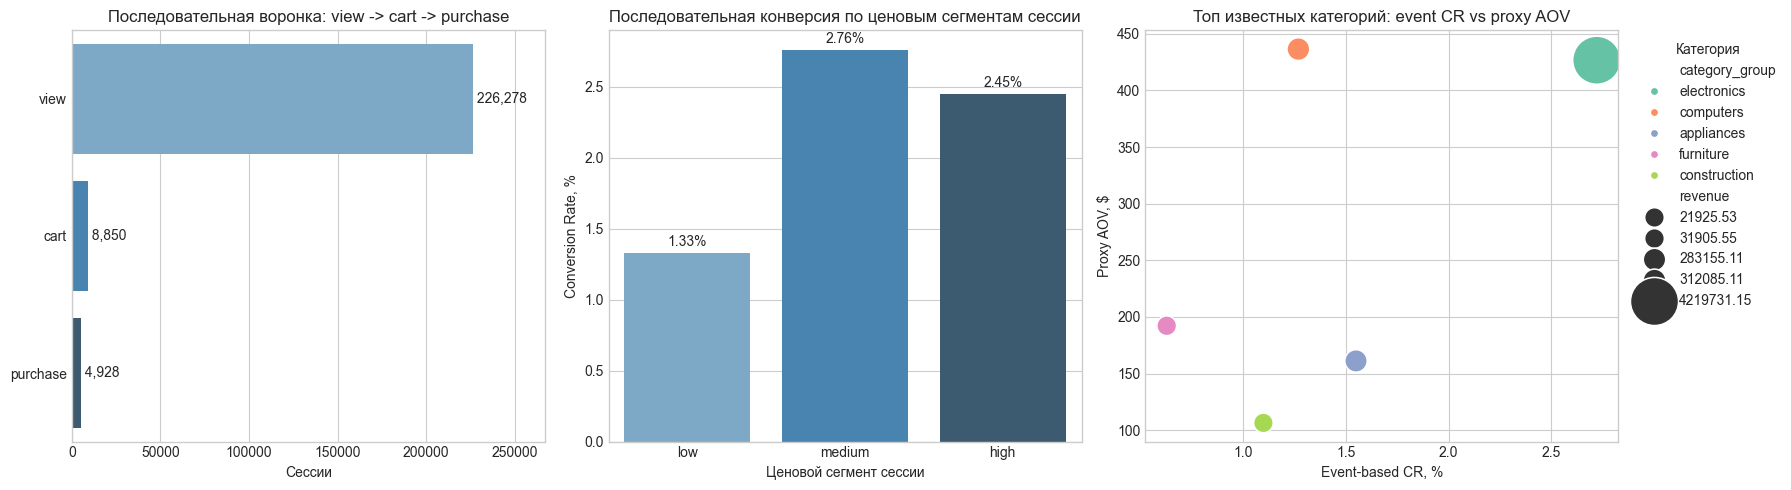

In [14]:
import os

os.makedirs('images', exist_ok=True)

style_name = (
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.style.use(style_name)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Последовательная воронка
funnel_plot = funnel_seq.reset_index().rename(columns={'index': 'stage'})

sns.barplot(
    data=funnel_plot,
    x='sessions',
    y='stage',
    hue='stage',
    legend=False,
    palette='Blues_d',
    ax=axes[0]
)

axes[0].set_title('Последовательная воронка: view -> cart -> purchase')
axes[0].set_xlabel('Сессии')
axes[0].set_ylabel('')
axes[0].set_xlim(0, funnel_plot['sessions'].max() * 1.18)

for i, row in funnel_plot.iterrows():
    axes[0].text(
        row['sessions'],
        i,
        f" {int(row['sessions']):,}",
        va='center'
    )

# 2. Ценовые сегменты
price_plot = price_funnel.copy()

sns.barplot(
    data=price_plot,
    x='session_price_category',
    y='overall_sequential_CR_%',
    hue='session_price_category',
    legend=False,
    palette='Blues_d',
    ax=axes[1]
)

axes[1].set_title('Последовательная конверсия по ценовым сегментам сессии')
axes[1].set_xlabel('Ценовой сегмент сессии')
axes[1].set_ylabel('Conversion Rate, %')

for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(
        f'{height:.2f}%',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points'
    )

# 3. Категории
if not known.empty:
    cat_plot = known.head(5).copy()

    sns.scatterplot(
        data=cat_plot,
        x='event_CR_%',
        y='proxy_AOV',
        size='revenue',
        sizes=(200, 1200),
        hue='category_group',
        palette='Set2',
        ax=axes[2]
    )

    axes[2].set_title('Топ известных категорий: event CR vs proxy AOV')
    axes[2].set_xlabel('Event-based CR, %')
    axes[2].set_ylabel('Proxy AOV, $')
    axes[2].legend(title='Категория', bbox_to_anchor=(1.02, 1), loc='upper left')
else:
    axes[2].text(
        0.5,
        0.5,
        'Нет данных по известным категориям',
        ha='center',
        va='center',
        transform=axes[2].transAxes
    )
    axes[2].set_title('Категории')

plt.tight_layout()

plt.savefig(
    '../images/funnel_and_category_analysis.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Бизнес-отчёт

## С чего начался пересчёт

Первую версию воронки я считал просто по наличию событий в сессии: сколько сессий видели `view`, сколько `cart`, сколько `purchase`. И там получилась неприятная вещь — сессий с покупкой оказалось больше, чем сессий с корзиной (14 316 против 8 894), а отношение purchase/cart вылезло за 160%. Так быть не должно, если это настоящая воронка. Поэтому я пересобрал всё по времени внутри сессии: первый `view` → `cart` после него → `purchase` после этого `cart`. И параллельно посчитал, сколько покупок происходит вообще без корзины.

Оказалось, что без корзины проходит большинство покупок. Это и есть главная находка работы, и она переписывает часть выводов первой версии.

## Последовательная воронка (через корзину)

| Этап | Сессии | Конверсия шага | Конверсия от view |
|---|---|---|---|
| view | 226 278 | — | 100.00% |
| cart | 8 850 | 3.91% | 3.91% |
| purchase | 4 928 | 55.68% | 2.18% |

Если человек всё-таки положил товар в корзину, он с вероятностью ~56% купит. Провал не здесь. Провал в том, что до корзины доходят лишь ~4% сессий с просмотром.

## Прямые покупки (мимо корзины)

Из всех сессий, где покупка случилась после просмотра (14 149), через корзину прошли только 4 928, а **9 221 (65.17%) купили напрямую**. Отсюда расхождение с первой версией: старые 6.33% — это доля всех сессий с покупкой без учёта порядка; если требовать покупку после просмотра, выйдет ~6.25%; а полный путь через корзину — уже 2.18%. Это не противоречие, это две разные метрики, и в отчёте я их теперь не смешиваю.

Прямой сценарий подтверждается и по категориям: в `computers` на 56 160 просмотров всего 144 события корзины, а в `apparel` и `sport` корзин нет вообще. Либо магазин реально даёт быстрый checkout, либо событие `cart` логируется не всегда. Для продуктовой команды это отдельный вопрос к instrumentation.

## Время

- Медиана от первого просмотра до первой покупки: **2.83 мин** (P25/P75: 1.33 / 6.15 мин).
- Медиана полной длительности сессий с покупкой: **3.95 мин**.

Это две разные вещи, и в первой версии я их путал, называя вторую «временем до покупки». Пользователь принимает решение быстро, чаще всего в пределах одной короткой сессии.

## Ценовые сегменты (на уровне сессии, взаимоисключающие)

Сегмент теперь назначаются сессии по максимальной цене товара внутри неё, поэтому одна сессия не прыгает между группами, как было раньше.

| Сегмент | Сессий с view | Покупок (через корзину) | Конверсия | cart → purchase |
|---|---|---|---|---|
| low | 75 426 | 1 000 | 1.33% | 49.36% |
| medium | 75 426 | 2 083 | 2.76% | 57.75% |
| high | 75 426 | 1 845 | 2.45% | 57.35% |

Средний сегмент конвертирует лучше всего, высокий рядом, а низкий отстаёт примерно вдвое. Причём в low хуже не только то, что кладут в корзину, но и то, что доводят её до покупки (49% против ~57–58%). Направление совпадает с первой версией, но цифры теперь чище, без пересечения сессий.

## Категории (event-based)

Здесь метрики по событиям, а не по сессиям: одна сессия может трогать несколько категорий, поэтому строгую сессионную воронку по категориям я не строю и подписываю это отдельно.

- `electronics` — основной бизнес: 77.63% всей выручки выборки, event CR 2.72%, proxy AOV $426.67.
- `computers` — высокий чек ($436.48) при низкой конверсии (1.27%) и почти мёртвой корзине. Зона, где деньги есть, а путь пользователя неочевиден.
- `appliances` — второй по выручке после электроники среди известных категорий, но чек заметно ниже ($161.16).
- `unknown` — 31.81% всех событий и 9.34% выручки. Много. Категорийные выводы ниже относятся в основном к товарам с известной категорией.

## Гипотезы и что бы я проверял дальше

1. **BNPL / рассрочка для `computers`.** Дорогой чек и низкая конверсия — классический кандидат на оплату частями прямо в карточке. На объёме выборки подъём event CR на +0.5 п.п. (с 1.27% до ~1.77%) даёт порядка +281 покупки и ориентировочно **+$120–125K** дополнительной выручки. Считаю это прокси-оценкой, не обещанием: точный эффект только через A/B и с учётом стоимости финансового продукта.

2. **Low-сегмент: доставка и кросс-селл.** Разрыв с medium (~1.4 п.п.) и по входу в корзину, и по дожатию — это похоже на барьер «невыгодно из-за доставки». Проверять бы порог бесплатной доставки и подсказки «добавьте ещё на $X». Денег тут не обещаю осознанно: у меня нет среднего чека по ценовым сессиям, поэтому гипотеза качественная и измеряется тестом, а не расчётом.

3. **Разобраться с корзиной как с явлением.** 65% покупок мимо неё и нулевые корзины в части категорий — это либо продукт (быстрый checkout), либо дыра в логах. Прежде чем «оживлять воронку корзины», надо понять, какой из двух случаев. Если это реальный сценарий — значит, усилия не туда направлялись; если потеря событий — это баг аналитики, который искажает любые будущие выводы.

## Ограничения

- Нет нормального `order_id` и количества товаров, поэтому AOV — это proxy по цене события `purchase`, а не настоящий средний чек заказа.
- Выборка обрезана до 1 млн событий, поэтому часть сессий обрывается на середине пути (покупка без предшествующего просмотра, корзина без просмотра и т.п.).
- `unknown` занимает треть событий — категорийная картина неполная.
- Категорийные метрики event-based и не сравнимы напрямую с сессионной воронкой.